<a href="https://colab.research.google.com/github/sianor23/ai-learning-journey/blob/main/Welcome_To_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28)  Test: (10000, 28, 28)


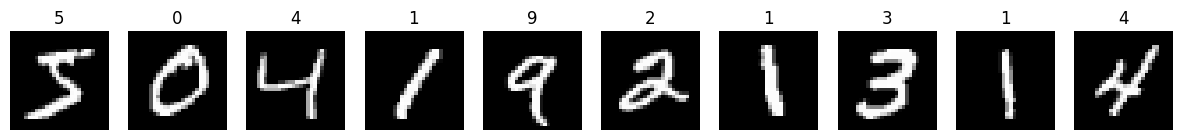

In [ ]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Train:", X_train.shape, " Test:", X_test.shape)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    axes[i].imshow(X_train[i], cmap="gray")
    axes[i].set_title(y_train[i])
    axes[i].axis("off")
plt.show()

In [ ]:
X_train_flat = X_train.reshape(60000, 784) / 255.0
X_test_flat = X_test.reshape(10000, 784) / 255.0
print(X_train_flat.shape, X_test_flat.shape, X_train_flat.min(), X_train_flat.max())

(60000, 784) (10000, 784) 0.0 1.0


In [ ]:
from sklearn.linear_model import Perceptron

all_weights, all_biases = [], []
for digit in range(10):
    y_binary = (y_train == digit).astype(int)
    model = Perceptron(eta0=0.1, max_iter=20, random_state=42)
    model.fit(X_train_flat, y_binary)
    all_weights.append(model.coef_[0])
    all_biases.append(model.intercept_[0])
    print(f"Perceptron for digit {digit} trained ✅")

Perceptron for digit 0 trained ✅
Perceptron for digit 1 trained ✅
Perceptron for digit 2 trained ✅
Perceptron for digit 3 trained ✅
Perceptron for digit 4 trained ✅
Perceptron for digit 5 trained ✅
Perceptron for digit 6 trained ✅
Perceptron for digit 7 trained ✅
Perceptron for digit 8 trained ✅
Perceptron for digit 9 trained ✅


In [ ]:
W = np.array(all_weights)
b = np.array(all_biases)

def predict(X):
    return np.argmax(X @ W.T + b, axis=1)

train_pred = predict(X_train_flat)
test_pred = predict(X_test_flat)
print("Train accuracy:", round((train_pred == y_train).mean() * 100, 1), "%")
print("Test accuracy:", round((test_pred == y_test).mean() * 100, 1), "%")

Train accuracy: 89.4 %
Test accuracy: 88.6 %


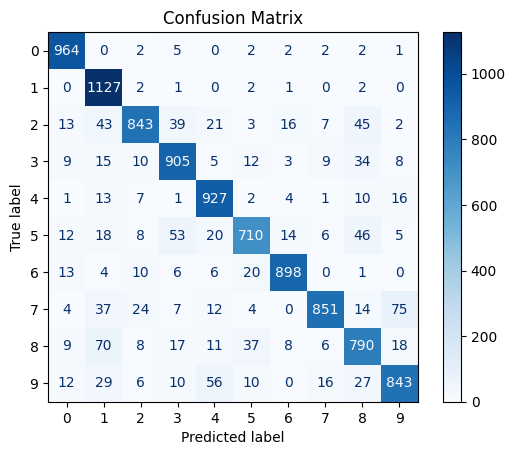

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()